<a href="https://colab.research.google.com/github/yashicam22/Stock-Scorecard/blob/main/week2%20Machine%20learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import yfinance as yf
import pandas as pd

raw = yf.download(['NVDA'], start='2023-01-01', group_by='ticker', auto_adjust=True)
df = raw['NVDA'].reset_index()
df['Ticker'] = 'NVDA'

[*********************100%***********************]  1 of 1 completed


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12,8), sharex=True)
axes[0].plot(df['Date'], df['Close'], label='Close')
axes[0].plot(df['Date'], df['SMA20'], label='SMA20')
axes[0].plot(df['Date'], df['SMA50'], label='SMA50')
axes[0].plot(df['Date'], df['VWAP20'], label='VWAP20')
axes[0].legend()

axes[1].plot(df['Date'], df['RSI14'])
axes[1].axhline(70, color='r', ls='--')
axes[1].axhline(30, color='g', ls='--')
axes[1].set_title('RSI14')

axes[2].plot(df['Date'], df['MACD'], label='MACD')
axes[2].plot(df['Date'], df['Signal'], label='Signal')
axes[2].legend()
plt.tight_layout()
plt.show()

In [ ]:
print(df.columns.tolist())

['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Ticker']


In [ ]:
df['Return'] = df['Close'].pct_change()
df['SMA20'] = df['Close'].rolling(20).mean()
df['SMA50'] = df['Close'].rolling(50).mean()
df['EMA20'] = df['Close'].ewm(span=20).mean()

chg = df['Close'].diff()
gain = chg.clip(lower=0).rolling(14).mean()
loss = (-chg.clip(upper=0)).rolling(14).mean()
df['RSI14'] = 100 - 100 / (1 + gain / loss)

tp = (df['High'] + df['Low'] + df['Close']) / 3
df['VWAP20'] = (tp * df['Volume']).rolling(20).sum() / df['Volume'].rolling(20).sum()

ema12, ema26 = df['Close'].ewm(span=12).mean(), df['Close'].ewm(span=26).mean()
df['MACD'] = ema12 - ema26
df['Signal'] = df['MACD'].ewm(span=9).mean()

print(df.columns.tolist())

['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Ticker', 'Return', 'SMA20', 'SMA50', 'EMA20', 'RSI14', 'VWAP20', 'MACD', 'Signal']


In [ ]:
print(df[['Date','Close','SMA20','RSI14','MACD','Signal']].tail(10))

Price       Date       Close       SMA20      RSI14      MACD    Signal
903   2026-08-11  217.500000  207.802998  54.255320  3.657090  1.638250
904   2026-08-12  224.089996  208.382498  61.404553  4.327948  2.176190
905   2026-08-13  225.300003  209.277499  63.879701  4.900752  2.721102
906   2026-08-14  225.160004  210.394999  75.439534  5.282513  3.233385
907   2026-08-17  225.009995  211.481499  75.017860  5.509448  3.688597
908   2026-08-18  219.740005  212.103999  77.411032  5.204062  3.991690
909   2026-08-19  217.559998  212.378999  71.915138  4.731590  4.139670
910   2026-08-20  216.850006  212.783500  67.356624  4.250861  4.161909
911   2026-08-21  214.720001  213.177500  59.479118  3.655864  4.060700
912   2026-08-24  210.229996  213.863500  47.955027  2.789859  3.806532


In [ ]:
print(df['SMA20'].iloc[-1], df['Close'].tail(20).mean())

213.86350021362304 213.86350021362304


In [ ]:
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

In [ ]:
def add_indicators(g):
    g = g.sort_values('Date').copy()
    g['Return'] = g['Close'].pct_change()
    g['SMA20'] = g['Close'].rolling(20).mean()
    g['SMA50'] = g['Close'].rolling(50).mean()
    g['EMA20'] = g['Close'].ewm(span=20).mean()

    chg = g['Close'].diff()
    gain = chg.clip(lower=0).rolling(14).mean()
    loss = (-chg.clip(upper=0)).rolling(14).mean()
    g['RSI14'] = 100 - 100 / (1 + gain / loss)

    tp = (g['High'] + g['Low'] + g['Close']) / 3
    g['VWAP20'] = (tp * g['Volume']).rolling(20).sum() / g['Volume'].rolling(20).sum()

    ema12, ema26 = g['Close'].ewm(span=12).mean(), g['Close'].ewm(span=26).mean()
    g['MACD'] = ema12 - ema26
    g['Signal'] = g['MACD'].ewm(span=9).mean()
    return g

data = data.groupby('Ticker', group_keys=False).apply(add_indicators)

NameError: name 'data' is not defined

In [ ]:
results = []
for ticker, g in data.groupby('Ticker'):
    results.append(add_indicators(g))
data = pd.concat(results, ignore_index=True)

In [ ]:
'data' in dir()

In [ ]:
df = data[data['Ticker'] == 'NVDA'].copy()
df['Return'] = df['Close'].pct_change()
df['SMA20'] = df['Close'].rolling(20).mean()
df['SMA50'] = df['Close'].rolling(50).mean()
df['EMA20'] = df['Close'].ewm(span=20).mean()

chg = df['Close'].diff()
gain = chg.clip(lower=0).rolling(14).mean()
loss = (-chg.clip(upper=0)).rolling(14).mean()
df['RSI14'] = 100 - 100 / (1 + gain / loss)

tp = (df['High'] + df['Low'] + df['Close']) / 3
df['VWAP20'] = (tp * df['Volume']).rolling(20).sum() / df['Volume'].rolling(20).sum()

ema12, ema26 = df['Close'].ewm(span=12).mean(), df['Close'].ewm(span=26).mean()
df['MACD'] = ema12 - ema26
df['Signal'] = df['MACD'].ewm(span=9).mean()

In [ ]:
print(df['SMA20'].iloc[-1], df['Close'].tail(20).mean())

213.85087509155272 213.85087509155272


In [ ]:
def add_indicators(g):
    g = g.sort_values('Date').copy()
    g['Return'] = g['Close'].pct_change()
    g['SMA20'] = g['Close'].rolling(20).mean()
    g['SMA50'] = g['Close'].rolling(50).mean()
    g['EMA20'] = g['Close'].ewm(span=20).mean()

    chg = g['Close'].diff()
    gain = chg.clip(lower=0).rolling(14).mean()
    loss = (-chg.clip(upper=0)).rolling(14).mean()
    g['RSI14'] = 100 - 100 / (1 + gain / loss)

    tp = (g['High'] + g['Low'] + g['Close']) / 3
    g['VWAP20'] = (tp * g['Volume']).rolling(20).sum() / g['Volume'].rolling(20).sum()

    ema12, ema26 = g['Close'].ewm(span=12).mean(), g['Close'].ewm(span=26).mean()
    g['MACD'] = ema12 - ema26
    g['Signal'] = g['MACD'].ewm(span=9).mean()
    return g

data = data.groupby('Ticker', group_keys=False).apply(add_indicators)
print(data.columns.tolist())

['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Ticker', 'Return', 'SMA20', 'SMA50', 'EMA20', 'RSI14', 'VWAP20', 'MACD', 'Signal']


/tmp/ipykernel_1407/2171898236.py:21: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data = data.groupby('Ticker', group_keys=False).apply(add_indicators)


In [ ]:
check = data.groupby('Ticker')['SMA20'].apply(lambda s: s.notna().sum())
print(check)

for t in data['Ticker'].unique():
    g = data[data['Ticker'] == t]
    manual = g['Close'].tail(20).mean()
    computed = g['SMA20'].iloc[-1]
    print(t, manual, computed, abs(manual - computed) < 1e-6)

Ticker
AAPL     894
AMZN     894
GOOGL    894
MSFT     894
NVDA     894
Name: SMA20, dtype: int64
NVDA 213.85087509155272 213.85087509155272 True
AAPL 313.0118408203125 313.0118408203125 True
MSFT 477.30713806152346 477.30713806152346 True
GOOGL 349.6314987182617 349.6314987182617 True
AMZN 262.9589988708496 262.9589988708496 True


In [ ]:
print(data['RSI14'].describe())
print((data['RSI14'] == float('inf')).sum())

count    4495.000000
mean       55.224649
std        16.782365
min         6.467017
25%        42.993174
50%        55.995120
75%        67.382650
max        98.629055
Name: RSI14, dtype: float64
0


In [ ]:
nvda = data[data['Ticker'] == 'NVDA']

print(nvda['RSI14'].describe())
print("Values above 100:", (nvda['RSI14'] > 100).sum())
print("Values below 0:", (nvda['RSI14'] < 0).sum())
print("Infinite values:", (nvda['RSI14'] == float('inf')).sum())
print("NaN count:", nvda['RSI14'].isna().sum())

count    899.000000
mean      57.196089
std       15.771416
min        8.187950
25%       44.680831
50%       57.452913
75%       68.776921
max       98.629055
Name: RSI14, dtype: float64
Values above 100: 0
Values below 0: 0
Infinite values: 0
NaN count: 14


In [ ]:
nvda = data[data['Ticker'] == 'NVDA']

print(nvda['RSI14'].describe())
print("Values above 100:", (nvda['RSI14'] > 100).sum())
print("Values below 0:", (nvda['RSI14'] < 0).sum())
print("Infinite values:", (nvda['RSI14'] == float('inf')).sum())
print("NaN count:", nvda['RSI14'].isna().sum())

count    899.000000
mean      57.196089
std       15.771416
min        8.187950
25%       44.680831
50%       57.452913
75%       68.776921
max       98.629055
Name: RSI14, dtype: float64
Values above 100: 0
Values below 0: 0
Infinite values: 0
NaN count: 14


In [ ]:
print(nvda[['MACD','Signal']].describe())
print("MACD NaN count:", nvda['MACD'].isna().sum())

Price        MACD      Signal
count  913.000000  913.000000
mean     1.487589    1.471169
std      3.043989    2.826969
min     -6.249304   -4.735604
25%     -0.310776   -0.180374
50%      0.922779    0.859032
75%      3.381268    3.233385
max      9.760091    8.842895
MACD NaN count: 0


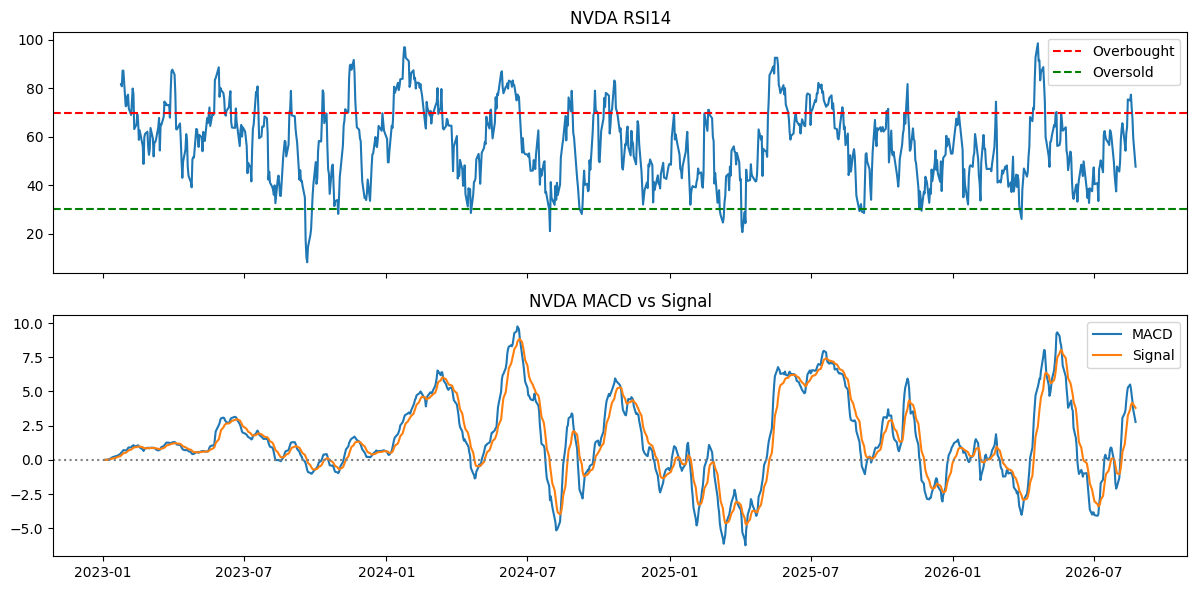

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(nvda['Date'], nvda['RSI14'])
axes[0].axhline(70, color='r', ls='--', label='Overbought')
axes[0].axhline(30, color='g', ls='--', label='Oversold')
axes[0].set_title('NVDA RSI14')
axes[0].legend()

axes[1].plot(nvda['Date'], nvda['MACD'], label='MACD')
axes[1].plot(nvda['Date'], nvda['Signal'], label='Signal')
axes[1].axhline(0, color='gray', ls=':')
axes[1].set_title('NVDA MACD vs Signal')
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
chg = df['Close'].diff()

gain = chg.clip(lower=0).rolling(14).mean()
loss = (-chg.clip(upper=0)).rolling(14).mean()

df['RSI14'] = 100 - 100 / (1 + gain / loss)

In [ ]:
df = data[data['Ticker'] == 'NVDA'].copy()